# 07 — q99 pre-shock HMM taxonomy

## Research question

Conditional on a native five-minute q99 volatility shock occurring at (t_0), do the **24 candles strictly before it** contain several recurring precursor trajectories?

Every asset-level q99 onset is treated as its own instance. The HMM sees only:

\[
t_0-120m,\ t_0-115m,\ldots,\ t_0-5m.
\]

\[
\boxed{t_0\text{ is never an HMM emission.}}
\]

This is not another q99 forecasting experiment. Modules 06b/06c already found that their full-chronology HMM states did not improve q99 forecasting beyond a simple volatility benchmark. Module 07 asks a different conditional question: **given that the shock happened, are the pre-shock paths themselves heterogeneous?**


## Two latent objects

1. **HMM state** = a recurring market configuration inside a pre-shock window.
2. **Shock type** = a cluster of the complete 24-bar HMM posterior trajectory.

The HMM is therefore used as a temporal representation of each shock's precursor path. It is not assumed that one HMM state equals one shock type.

Shock sign, event magnitude, synchronization, prior-q99/aftershock status, asset and date are **not used in fitting**. They are examined only after the unsupervised taxonomy has been formed.


In [1]:
from pathlib import Path
import json, os, sys, warnings
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from dotenv import load_dotenv

warnings.filterwarnings('ignore', category=RuntimeWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 220)
pd.set_option('display.width', 340)
pd.set_option('display.max_rows', 300)

load_dotenv()
DATA_ROOT = Path(os.environ['DERIBIT_DATA_ROOT']).expanduser().resolve()
DB_PATH = DATA_ROOT / 'database' / 'research.duckdb'
PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    raise RuntimeError('Repository root not found.')
SRC = PROJECT_ROOT / 'src'
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from data_engineering.modeling import volatility_vd_b_core as vb
from data_engineering.modeling import volatility_hmm_states_b as hb
from data_engineering.modeling import volatility_q99_preshock_hmm as v7

START = os.getenv('VD7_START', '').strip() or None
END = os.getenv('VD7_END', '').strip() or None
ASSETS = [x.strip().upper() for x in os.getenv('VD7_ASSETS', '').split(',') if x.strip()]
DISCOVERY_FRACTION = float(os.getenv('VD7_DISCOVERY_FRACTION', str(v7.DEFAULT_DISCOVERY_FRACTION)))
K_VALUES = tuple(int(x) for x in os.getenv('VD7_K', '2,3,4,5').split(',') if x.strip())
N_INIT = int(os.getenv('VD7_N_INIT', str(v7.DEFAULT_N_INIT)))
MAX_ITER = int(os.getenv('VD7_MAX_ITER', str(v7.DEFAULT_MAX_ITER)))
CLUSTER_K = tuple(int(x) for x in os.getenv('VD7_CLUSTER_K', '2,3,4').split(',') if x.strip())
CLUSTER_N_INIT = int(os.getenv('VD7_CLUSTER_N_INIT', str(v7.DEFAULT_CLUSTER_N_INIT)))
MIN_L2_WINDOW_COVERAGE = float(os.getenv('VD7_MIN_L2_WINDOW_COVERAGE', '0.75'))
OUT = PROJECT_ROOT / 'notebooks' / 'Volatility_Dynamics' / '07'
OUT.mkdir(parents=True, exist_ok=True)

print('Module 07 engine:', v7.VERSION)
print('selftest:', v7.selftest())
print('HMM K grid:', K_VALUES, '| shock-type grid:', CLUSTER_K)


Module 07 engine: 0.1.0
selftest: {'t0_excluded_24_bar_sequences': True, 'missing_emissions_supported': True, 'timestamp_weighted_hmm': True, 'posterior_trajectory_clustering': True}
HMM K grid: (2, 3, 4, 5) | shock-type grid: (2, 3, 4)


## 1. Frozen −95m feature families

The source fields are the features carried by the Module 05 motif study. To avoid letting correlated representations manufacture HMM states, they are aggregated into four normalized family emissions:

- **activity:** intrabar range, USD volume, trade count;
- **IV level:** ATM forward IV, 25d put IV, 25d call IV;
- **liquidity/book activity:** spread, book update count;
- **L2 instability:** OBI zero-cross count/rate, transition count, path roughness.

The L2 family may be missing before L2 collection begins; the HMM marginalizes missing emission dimensions rather than discarding the entire sequence.


In [2]:
con = duckdb.connect(str(DB_PATH), read_only=True)
schema = con.execute('DESCRIBE time_series_feature_state').df()
available = set(schema.column_name.astype(str))
contract = v7.feature_contract(available)
display(contract)
missing = contract.loc[~contract.present, 'feature'].tolist()
if missing:
    raise RuntimeError(f'Missing Module 07 source features: {missing}')


,feature,family,present,module05_origin,used_only_before_t0
0,intrabar_range_bps,activity,True,True,True
1,volume_usd,activity,True,True,True
2,trade_count,activity,True,True,True
3,option_iv_atm_forward,iv_level,True,True,True
4,iv_put_25d,iv_level,True,True,True
5,iv_call_25d,iv_level,True,True,True
6,book_twa_spread_bps,liquidity_book_activity,True,True,True
7,book_update_count,liquidity_book_activity,True,True,True
8,book_obi_20_raw_zero_cross_count,l2_instability,True,True,True
9,book_obi_20_transition_count,l2_instability,True,True,True


## 2. Load the common five-minute panel


In [3]:
def qident(name):
    return '"' + str(name).replace('"', '""') + '"'

cols = ['state_time','underlying','return_5m'] + list(v7.SOURCE_FEATURES)
where = []
if START:
    ts = pd.Timestamp(START)
    ts = ts.tz_localize('UTC') if ts.tzinfo is None else ts.tz_convert('UTC')
    where.append(f"state_time >= TIMESTAMPTZ '{ts.isoformat()}'")
if END:
    ts = pd.Timestamp(END)
    ts = ts.tz_localize('UTC') if ts.tzinfo is None else ts.tz_convert('UTC')
    end_ts = ts + pd.Timedelta(days=1)
    where.append(f"state_time < TIMESTAMPTZ '{end_ts.isoformat()}'")
if ASSETS:
    where.append('underlying IN (' + ','.join(repr(x) for x in ASSETS) + ')')
where_sql = '' if not where else ' WHERE ' + ' AND '.join(where)
sql = 'SELECT ' + ', '.join(qident(c) for c in cols) + ' FROM time_series_feature_state' + where_sql + ' ORDER BY underlying,state_time'
df = con.execute(sql).df()
con.close()
df['state_time'] = pd.to_datetime(df.state_time, utc=True)
df = df.reset_index(drop=True)
if df.empty:
    raise RuntimeError('No rows found.')
if df.duplicated(['underlying','state_time']).any():
    raise RuntimeError('Duplicate asset/timestamp rows found.')
grid = vb.build_grid(df)
print(f'rows {len(df):,} | assets {grid.assets}')
print(df.state_time.min(), '->', df.state_time.max())


rows 42,336 | assets ['AVAX', 'BTC', 'ETH', 'HYPE', 'SOL', 'TRX', 'XRP']
2026-09-19 08:00:00+00:00 -> 2026-10-10 07:55:00+00:00


## 3. Recompute all q99 onsets and extract exact pre-shock windows

The event definition matches the original Modules 03–05: full-sample per-asset q99 of native (r_t^2), with consecutive q99 bars reduced to run onsets.

For every onset we extract exactly 24 rows at offsets (-24\ldots-1). The event row at offset 0 is retained only in the catalog for post-hoc shock description.


In [4]:
events, q99_thresholds, tail, onset = v7.event_catalog(grid)
windows, window_audit = v7.exact_preshock_windows(grid, events)
events = events.merge(window_audit[['event_id','exact_24bar_window','n_rows_found']], on='event_id', how='left')
usable_mask = events.exact_24bar_window.to_numpy(bool)
events_u = events.loc[usable_mask].reset_index(drop=True)
windows_u = [w for w, ok in zip(windows, usable_mask) if ok]
if len(events_u) < 30:
    raise RuntimeError('Too few complete q99 pre-shock windows.')
print('all q99 asset-events:', len(events), '| usable exact 24-bar windows:', len(events_u))
print('unique usable q99 timestamps:', events_u.event_time.nunique())
display(events_u[['underlying','event_time','variance_threshold_multiple','event_direction','n_assets_q99_same_time','has_prior_q99_bar_120m']].head(30))


all q99 asset-events: 337 | usable exact 24-bar windows: 337
unique usable q99 timestamps: 198


,underlying,event_time,variance_threshold_multiple,event_direction,n_assets_q99_same_time,has_prior_q99_bar_120m
0,AVAX,2026-09-21 17:55:00+00:00,2.137812,down,1,False
1,AVAX,2026-09-22 15:25:00+00:00,1.009992,up,1,False
2,AVAX,2026-09-23 03:50:00+00:00,2.070561,down,1,False
3,AVAX,2026-09-23 10:40:00+00:00,1.005109,up,1,False
4,AVAX,2026-09-23 12:05:00+00:00,5.384890,down,1,True
5,AVAX,2026-09-23 13:55:00+00:00,1.497688,up,1,True
6,AVAX,2026-09-23 14:10:00+00:00,1.541245,down,5,True
7,AVAX,2026-09-23 14:35:00+00:00,1.712070,up,6,True
8,AVAX,2026-09-23 16:10:00+00:00,1.753995,up,6,True
9,AVAX,2026-09-24 05:35:00+00:00,1.094807,down,1,False


## 4. L2-covered primary sample and chronological discovery/validation split

The −95m hypothesis is especially tied to L2 instability, but those fields begin later than the broad activity/IV data.

The **primary HMM/taxonomy is therefore fitted only on q99 windows with at least 75% finite L2-family source observations across the 24 pre-shock bars** (configurable with `VD7_MIN_L2_WINDOW_COVERAGE`).

This prevents the discovery HMM from silently ignoring the feature family that motivated Module 07.

All exact 24-bar q99 windows are still retained. After the L2-era taxonomy is frozen, earlier shocks with missing L2 can be projected into it with the L2 dimension marginalized; those assignments are explicitly labeled `historical_missing_l2` and are not used for model selection or validation.

Discovery/validation is split by unique q99 timestamp inside the L2-covered primary sample. All assets sharing a timestamp remain on the same side.

Source-feature normalization uses asset × UTC hour and is estimated only from panel rows before the first validation shock timestamp.


In [5]:
source_E = v7.source_emissions(grid)
l2_source_cols = list(v7.FAMILY_SOURCES['l2_instability'])
l2_source_idx = [source_E.columns.get_loc(c) for c in l2_source_cols]
source_arr = source_E.to_numpy(float)

l2_cov = []
for w in windows_u:
    x = source_arr[np.ix_(w, l2_source_idx)]
    # fraction of bars with at least one observable L2 motif source
    bar_has_l2 = np.isfinite(x).any(axis=1)
    l2_cov.append(float(bar_has_l2.mean()))
events_u['l2_window_coverage'] = np.asarray(l2_cov, float)

model_mask = events_u.l2_window_coverage.to_numpy(float) >= MIN_L2_WINDOW_COVERAGE
events_model = events_u.loc[model_mask].reset_index(drop=True)
windows_model = [w for w, ok in zip(windows_u, model_mask) if ok]
events_hist = events_u.loc[~model_mask].reset_index(drop=True)
windows_hist = [w for w, ok in zip(windows_u, model_mask) if not ok]

if events_model.event_time.nunique() < 10:
    raise RuntimeError(
        f'Only {events_model.event_time.nunique()} unique q99 timestamps satisfy '
        f'L2 window coverage >= {MIN_L2_WINDOW_COVERAGE:.2f}; not enough for Module 07.'
    )

split_time, is_discovery, is_validation = v7.split_events_by_unique_time(events_model, DISCOVERY_FRACTION)
events_model['sample'] = np.where(is_discovery, 'discovery', 'validation')
print('primary L2-covered asset-events:', len(events_model), '| unique timestamps:', events_model.event_time.nunique())
print('historical/missing-L2 projection events:', len(events_hist))
print('validation starts:', split_time)
display(events_model.groupby('sample').agg(asset_events=('event_id','size'), unique_times=('event_time','nunique'), assets=('underlying','nunique')))

normalizer_train_mask = grid.time_ns < pd.Timestamp(split_time).value
normalizer = hb.fit_hour_normalizer(grid, source_E, normalizer_train_mask)
source_Z = hb.apply_normalizer(grid, source_E, normalizer)
family_Z, family_names = v7.family_scores_from_source_z(source_Z, source_E.columns)
family_Z_spread_only, _ = v7.family_scores_from_source_z(
    source_Z, source_E.columns, spread_only_liquidity=True
)
print('families:', family_names)


primary L2-covered asset-events: 96 | unique timestamps: 58
historical/missing-L2 projection events: 241
validation starts: 2026-10-08 04:20:00+00:00


,asset_events,unique_times,assets
sample,,,
discovery,62,40,7
validation,34,18,7


families: ['activity', 'iv_level', 'liquidity_book_activity', 'l2_instability']


## 5. Window coverage audit

A pre-shock row can still have one missing family. Missing dimensions are marginalized by the HMM. This cell makes the available information explicit rather than silently imputing it.


In [6]:
coverage_rows = []
for ev, seq in zip(events_u.itertuples(), windows_u):
    sample = (
        events_model.set_index('event_id').at[int(ev.event_id), 'sample']
        if int(ev.event_id) in set(events_model.event_id.astype(int))
        else 'historical_missing_l2'
    )
    for j, fam in enumerate(family_names):
        finite = np.isfinite(family_Z[seq, j])
        coverage_rows.append({
            'event_id': int(ev.event_id), 'sample': sample, 'underlying': ev.underlying,
            'event_time': ev.event_time, 'family': fam,
            'n_finite_bars': int(finite.sum()), 'coverage_24bars': float(finite.mean()),
            'l2_window_coverage': float(ev.l2_window_coverage),
        })
coverage = pd.DataFrame(coverage_rows)
display(coverage.groupby(['sample','family']).coverage_24bars.describe().round(3))


count   mean    std    min  25%  50%  75%    max
sample                family                                                                   
discovery             activity                  62.0  1.000  0.000  1.000  1.0  1.0  1.0  1.000
                      iv_level                  62.0  0.997  0.010  0.958  1.0  1.0  1.0  1.000
                      l2_instability            62.0  1.000  0.000  1.000  1.0  1.0  1.0  1.000
                      liquidity_book_activity   62.0  1.000  0.000  1.000  1.0  1.0  1.0  1.000
historical_missing_l2 activity                 241.0  1.000  0.000  1.000  1.0  1.0  1.0  1.000
                      iv_level                 241.0  0.997  0.010  0.958  1.0  1.0  1.0  1.000
                      l2_instability           241.0  0.001  0.011  0.000  0.0  0.0  0.0  0.167
                      liquidity_book_activity  241.0  0.921  0.270  0.000  1.0  1.0  1.0  1.000
validation            activity                  34.0  1.000  0.000  1.000  1.0  1.0  1.0  1.000
                      iv_level                  34.0  1.000  0.000  1.000  1.0  1.0  1.0  1.000
                      l2_instability            34.0  1.000  0.000  1.000  1.0  1.0  1.0  1.000
                      liquidity_book_activity   34.0  1.000  0.000  1.000  1.0  1.0  1.0  1.000

## 6. Fit the pre-shock HMM

Each 24-bar event window is one HMM sequence. Simultaneous asset-events receive weights (1/n\) so one broad crypto shock has total fitting weight one rather than up to seven.

The HMM state count is selected by discovery-sample BIC with a state-occupancy guard. Validation sequence likelihood is reported only as a stability diagnostic.


In [7]:
disc_events = events_model.loc[is_discovery].reset_index(drop=True)
val_events = events_model.loc[is_validation].reset_index(drop=True)
disc_windows = [w for w, m in zip(windows_model, is_discovery) if m]
val_windows = [w for w, m in zip(windows_model, is_validation) if m]
disc_seq = [family_Z[w] for w in disc_windows]
val_seq = [family_Z[w] for w in val_windows]
disc_w = v7.event_weights(disc_events)
val_w = v7.event_weights(val_events)

hmm_compare, hmm_models = v7.hmm_model_grid(
    disc_seq, disc_w, val_seq, val_w,
    k_values=K_VALUES, n_init=N_INIT, max_iter=MAX_ITER,
)
selected_k = int(hmm_compare.loc[hmm_compare.selected_by_bic, 'K'].iloc[0])
model = hmm_models[selected_k]
print('selected pre-shock HMM K:', selected_k)
display(hmm_compare.round(5))


selected pre-shock HMM K: 5


,K,n_features,effective_discovery_rows,effective_validation_rows,weighted_train_loglik_per_effective_row,weighted_validation_loglik_per_effective_row,bic_effective_train,min_state_occupancy,max_state_occupancy,n_converged_initializations,best_seed,k_at_grid_edge,selected_by_bic
0,2,4,960.0,432.0,-4.19642,-5.49558,8187.58980,0.37671,0.62329,4,7270,False,False
1,3,4,960.0,432.0,-3.77903,-5.02463,7475.48786,0.22081,0.48750,4,7370,False,False
2,4,4,960.0,432.0,-3.54386,-5.49320,7126.95707,0.15168,0.40137,4,7472,False,False
3,5,4,960.0,432.0,-3.40317,-5.51048,6973.56287,0.11043,0.41911,4,7573,True,True


## 7. What do the pre-shock HMM states represent?

These are unlabeled phases. Their emission means are robust-z family levels relative to the asset/hour training baseline.


In [8]:
hmm_emissions = v7.hmm_emission_table(model, family_names)
hmm_transitions = v7.hmm_transition_table(model)
display(hmm_emissions.pivot(index='state', columns='family', values='mean_robust_z').round(3))
display(hmm_transitions.pivot(index='from_state', columns='to_state', values='probability').round(3))


family,activity,iv_level,l2_instability,liquidity_book_activity
state,,,,
0,0.322,-1.201,-0.529,-0.817
1,0.463,0.097,0.203,0.150
2,0.129,-0.718,0.595,0.244
3,1.297,0.380,0.865,0.802
4,0.020,-0.510,-0.341,-0.312


to_state,0,1,2,3,4
from_state,,,,,
0,0.914,0.051,0.001,0.013,0.021
1,0.020,0.931,0.000,0.045,0.003
2,0.003,0.000,0.987,0.010,0.000
3,0.000,0.091,0.015,0.895,0.000
4,0.027,0.038,0.005,0.000,0.930


## 8. Encode every shock by its entire posterior state trajectory

The HMM is smoothed **within the pre-shock window only**. This is acceptable for retrospective taxonomy because all 24 observations are known by (t_0-5m); no (t_0) or post-shock observation is used.

Each shock embedding contains six consecutive 20-minute state-occupancy blocks, plus the exact −95m posterior and the terminal −5m posterior.


In [9]:
disc_paths, disc_embed_raw = v7.posterior_paths(model, disc_seq, disc_events, sample='discovery')
val_paths, val_embed_raw = v7.posterior_paths(model, val_seq, val_events, sample='validation')
disc_embed, val_embed, embed_mu, embed_sd = v7.standardize_embeddings(disc_embed_raw, val_embed_raw)
print('embedding dimension:', disc_embed.shape[1])


embedding dimension: 40


## 9. Discover candidate shock types

Shock types are weighted k-means clusters of the discovery posterior-trajectory embeddings. Candidate counts are 2–4. Selection uses weighted silhouette with a minimum effective cluster size of five unique-timestamp equivalents.

Validation shocks are assigned to the frozen discovery centroids; they do not refit the taxonomy.


In [10]:
cluster_compare, n_types, disc_labels, val_labels, centers = v7.fit_shock_clusters(
    disc_embed, disc_w, val_embed,
    cluster_values=CLUSTER_K, n_init=CLUSTER_N_INIT,
)
print('selected number of shock types:', n_types)
display(cluster_compare.round(4))

disc_assign = v7.assignment_table(disc_events, disc_labels, 'discovery')
val_assign = v7.assignment_table(val_events, val_labels, 'validation')

hist_paths = pd.DataFrame()
hist_assign = pd.DataFrame()
hist_embed_raw = np.empty((0, disc_embed_raw.shape[1]))
if len(events_hist):
    hist_seq = [family_Z[w] for w in windows_hist]
    hist_paths, hist_embed_raw = v7.posterior_paths(
        model, hist_seq, events_hist, sample='historical_missing_l2'
    )
    hist_embed = (hist_embed_raw - embed_mu) / embed_sd
    hist_dist = np.column_stack([
        np.sum((hist_embed - c) ** 2, axis=1) for c in centers
    ])
    hist_labels = np.argmin(hist_dist, axis=1)
    hist_assign = v7.assignment_table(
        events_hist, hist_labels, 'historical_missing_l2'
    )

assignments = pd.concat([disc_assign, val_assign, hist_assign], ignore_index=True)
assignments = assignments.merge(
    events_u[['event_id','l2_window_coverage']],
    on='event_id', how='left'
)
display(assignments.head(30))


selected number of shock types: 2


,n_shock_types,weighted_inertia,weighted_silhouette,min_effective_cluster_timestamps,max_effective_cluster_timestamps,selected
0,2,1179.4287,0.2380,16.5167,23.4833,True
1,3,939.3411,0.3146,4.5548,23.4833,False
2,4,714.2687,0.3854,3.7857,23.4833,False


,event_id,underlying,event_time,event_return_5m,event_variance_5m,q99_threshold,variance_threshold_multiple,event_direction,n_assets_q99_same_time,has_prior_q99_bar_120m,n_prior_q99_bars_120m,minutes_since_latest_prior_q99,collector_l2_era,sample,shock_type,l2_window_coverage
0,38,AVAX,2026-10-01 15:10:00+00:00,-0.010634,0.000113,0.000098,1.148075,down,1,False,0,NaN,False,discovery,0,1.0
1,39,AVAX,2026-10-02 18:20:00+00:00,-0.009926,0.000099,0.000098,1.000352,down,1,False,0,NaN,False,discovery,1,1.0
2,40,AVAX,2026-10-02 18:40:00+00:00,-0.022992,0.000529,0.000098,5.367310,down,7,True,1,20.0,False,discovery,1,1.0
3,41,AVAX,2026-10-06 12:10:00+00:00,0.010004,0.000100,0.000098,1.016244,up,1,False,0,NaN,True,discovery,1,1.0
4,42,AVAX,2026-10-06 12:20:00+00:00,-0.011121,0.000124,0.000098,1.255816,down,1,True,1,10.0,True,discovery,1,1.0
5,43,AVAX,2026-10-07 02:00:00+00:00,-0.013836,0.000191,0.000098,1.943623,down,4,False,0,NaN,True,discovery,0,1.0
6,44,AVAX,2026-10-07 13:55:00+00:00,0.010739,0.000115,0.000098,1.170955,up,5,False,0,NaN,True,discovery,1,1.0
7,81,BTC,2026-10-01 15:50:00+00:00,0.004325,0.000019,0.000013,1.397432,up,1,False,0,NaN,False,discovery,0,1.0
8,82,BTC,2026-10-01 17:20:00+00:00,0.003853,0.000015,0.000013,1.108710,up,1,True,1,90.0,False,discovery,0,1.0
9,83,BTC,2026-10-02 04:20:00+00:00,0.005779,0.000033,0.000013,2.494812,up,1,False,0,NaN,False,discovery,0,1.0


## 10. Are the types different in their actual precursor feature paths?

The shock labels were formed from HMM posterior trajectories, not from shock outcomes. This cell maps each type back to the four observed family paths from −120m to −5m.


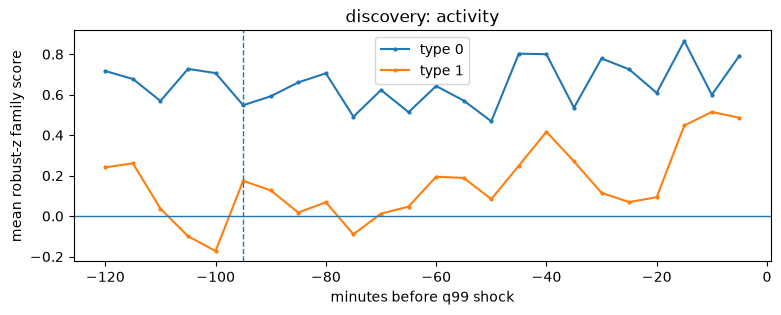

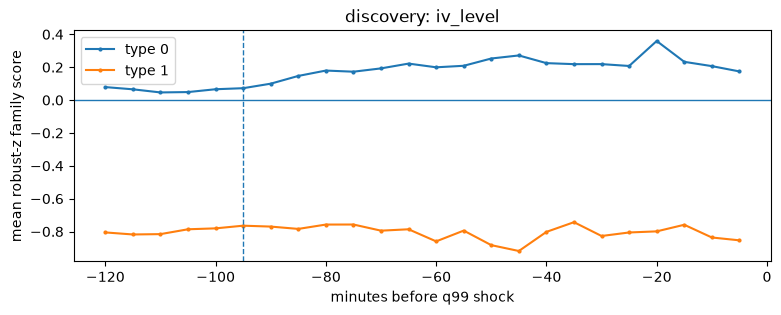

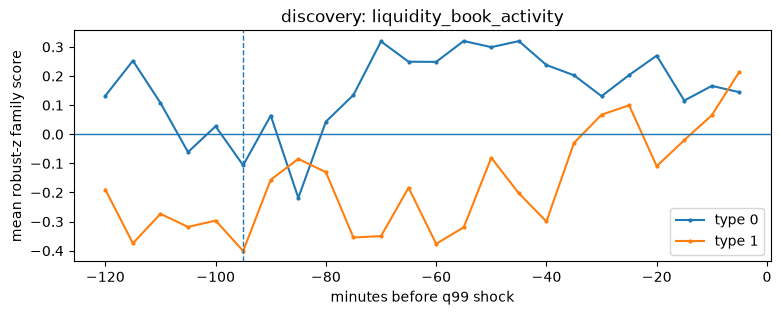

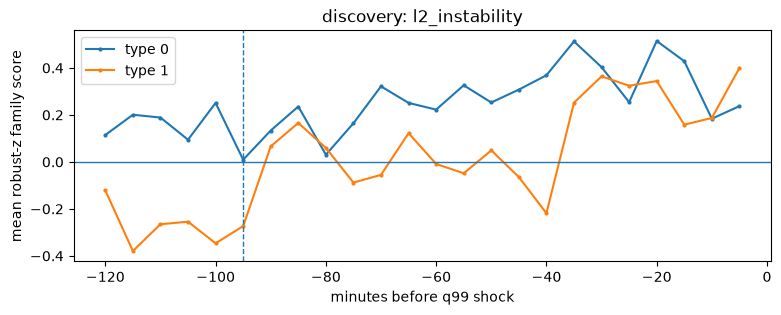

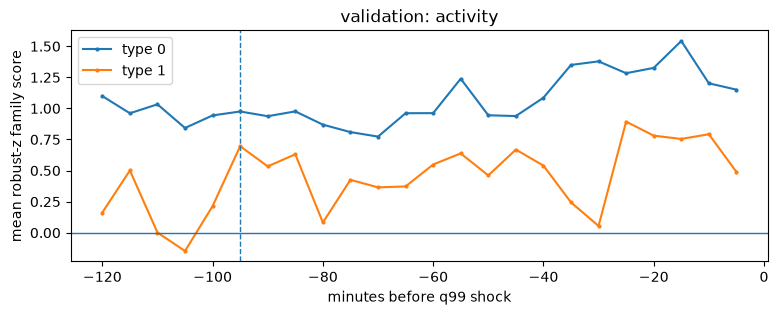

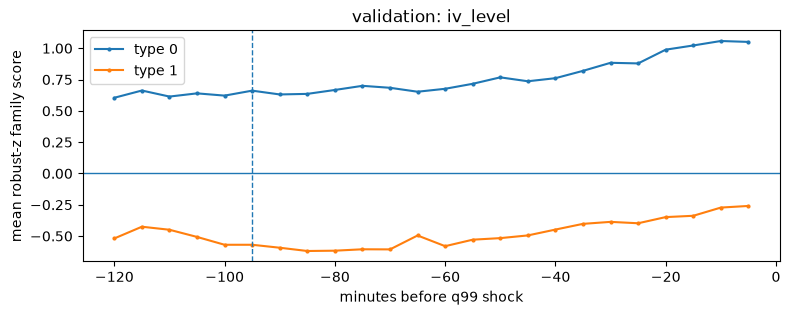

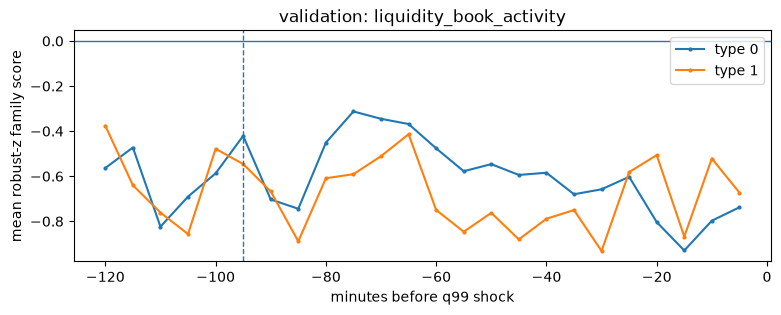

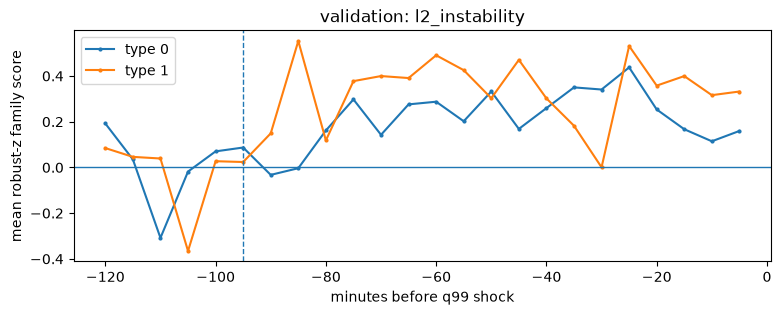

In [11]:
profile_parts = [
    v7.family_profile_table(family_Z, grid, disc_windows, disc_assign, family_names),
    v7.family_profile_table(family_Z, grid, val_windows, val_assign, family_names),
]
if len(hist_assign):
    profile_parts.append(
        v7.family_profile_table(family_Z, grid, windows_hist, hist_assign, family_names)
    )
family_profiles = pd.concat(profile_parts, ignore_index=True)

for sample in ['discovery','validation']:
    for fam in family_names:
        g = family_profiles[(family_profiles['sample']==sample) & (family_profiles.family==fam)]
        if g.empty:
            continue
        fig, ax = plt.subplots(figsize=(9,3))
        for typ, h in g.groupby('shock_type'):
            h = h.sort_values('rel_min')
            ax.plot(h.rel_min, h.mean_family_z, marker='o', markersize=2, label=f'type {typ}')
        ax.axvline(-95, linestyle='--', linewidth=1)
        ax.axhline(0, linewidth=1)
        ax.set_title(f'{sample}: {fam}')
        ax.set_xlabel('minutes before q99 shock')
        ax.set_ylabel('mean robust-z family score')
        ax.legend()
        plt.show()


## 11. HMM-state trajectories by shock type


In [12]:
disc_type_map = dict(zip(disc_assign.event_id.astype(int), disc_assign.shock_type.astype(int)))
val_type_map = dict(zip(val_assign.event_id.astype(int), val_assign.shock_type.astype(int)))
disc_paths['shock_type'] = disc_paths.event_id.astype(int).map(disc_type_map)
val_paths['shock_type'] = val_paths.event_id.astype(int).map(val_type_map)
path_parts = [disc_paths, val_paths]
if len(hist_assign):
    hist_type_map = dict(zip(hist_assign.event_id.astype(int), hist_assign.shock_type.astype(int)))
    hist_paths['shock_type'] = hist_paths.event_id.astype(int).map(hist_type_map)
    path_parts.append(hist_paths)
all_paths = pd.concat(path_parts, ignore_index=True)
state_profiles = v7.state_profile_table(all_paths)
display(state_profiles.head(40).round(4))


,sample,shock_type,rel_bar,rel_min,p_state_0,p_state_1,p_state_2,p_state_3,p_state_4,n_unique_event_times
0,discovery,0,-24,-120,0.0414,0.6306,0.0000,0.1737,0.1543,26
1,discovery,0,-23,-115,0.0058,0.6935,0.0000,0.1686,0.1321,26
2,discovery,0,-22,-110,0.0121,0.7033,0.0000,0.1652,0.1194,26
3,discovery,0,-21,-105,0.0476,0.7523,0.0000,0.1198,0.0803,26
4,discovery,0,-20,-100,0.0580,0.7511,0.0000,0.1398,0.0512,26
5,discovery,0,-19,-95,0.0591,0.7544,0.0000,0.1356,0.0509,26
6,discovery,0,-18,-90,0.0648,0.7569,0.0000,0.1119,0.0664,26
7,discovery,0,-17,-85,0.0994,0.6222,0.0000,0.2205,0.0579,26
8,discovery,0,-16,-80,0.1289,0.5809,0.0000,0.2361,0.0541,26
9,discovery,0,-15,-75,0.0940,0.6271,0.0000,0.2342,0.0447,26


## 12. Only now inspect what each shock type corresponds to

These descriptors were not used in the HMM or clustering. They tell us whether an unsupervised precursor type later turns out to correspond to:

- larger/smaller q99 shocks;
- upward/downward shocks;
- synchronized market-wide shocks;
- recent-q99/aftershock sequences;
- a particular asset;
- a particular date or the post-L2 collector era.

A type dominated by one date/asset/collector era is a warning sign, not an economic discovery.


In [13]:
descriptors = v7.shock_type_descriptors(assignments)
asset_composition, date_composition = v7.composition_tables(assignments)
display(descriptors.round(4))
display(asset_composition.sort_values(['sample','shock_type','share_within_type'], ascending=[True,True,False]).head(100).round(4))
display(date_composition.sort_values(['sample','shock_type','share_within_type'], ascending=[True,True,False]).head(100).round(4))


,sample,shock_type,n_asset_events,n_unique_event_times,n_assets,mean_variance_threshold_multiple,median_variance_threshold_multiple,share_up_shocks,share_synchronized_ge5,share_prior_q99_120m,mean_sync_assets,share_l2_collector_era
0,discovery,0,31,26,6,1.6082,1.2741,0.4194,0.0645,0.2258,1.8710,0.3548
1,discovery,1,31,18,7,2.0836,1.3338,0.4194,0.3226,0.1290,3.4194,0.5484
2,historical_missing_l2,0,224,131,7,1.9785,1.4734,0.4777,0.3438,0.4911,3.0714,0.0000
3,historical_missing_l2,1,17,16,6,2.4460,1.4069,0.5882,0.1765,0.1765,2.4118,0.0000
4,validation,0,29,15,7,1.5593,1.3458,0.5172,0.3448,0.6207,3.1379,1.0000
5,validation,1,5,5,3,1.5957,1.7294,0.2000,0.0000,0.4000,2.2000,1.0000


,sample,shock_type,underlying,n_asset_events,share_within_type
1,discovery,0,BTC,10,0.3226
2,discovery,0,ETH,8,0.2581
3,discovery,0,HYPE,5,0.1613
5,discovery,0,TRX,4,0.1290
0,discovery,0,AVAX,2,0.0645
4,discovery,0,SOL,2,0.0645
11,discovery,1,TRX,8,0.2581
6,discovery,1,AVAX,5,0.1613
10,discovery,1,SOL,5,0.1613
8,discovery,1,ETH,4,0.1290


,sample,shock_type,event_date,n_asset_events,share_within_type
1,discovery,0,2026-10-02,13,0.4194
0,discovery,0,2026-10-01,7,0.2258
3,discovery,0,2026-10-05,5,0.1613
4,discovery,0,2026-10-07,5,0.1613
2,discovery,0,2026-10-04,1,0.0323
5,discovery,1,2026-10-02,12,0.3871
10,discovery,1,2026-10-07,9,0.2903
7,discovery,1,2026-10-04,3,0.0968
8,discovery,1,2026-10-05,3,0.0968
9,discovery,1,2026-10-06,2,0.0645


## 13. Does the taxonomy persist in later shocks?

Validation events are assigned to discovery centroids. A candidate type is more credible if it receives non-trivial validation weight and its validation trajectory remains close to the discovery centroid.


In [14]:
stability = v7.validation_stability(
    disc_embed, val_embed, disc_labels, val_labels, centers, disc_w, val_w
)
display(stability.round(4))


,shock_type,discovery_effective_timestamps,validation_effective_timestamps,validation_centroid_rms_drift,validation_mean_distance_to_discovery_centroid
0,0,23.4833,14.5,0.5622,5.7135
1,1,16.5167,3.5,0.5088,6.1161


## 14. Collector-shift sensitivity

Claude's 06b review flagged `book_update_count` as potentially affected by the 2026-10-04 collector change. We therefore rerun the entire HMM+taxonomy with the liquidity family defined from **spread only**, while keeping the other three families identical.

The Adjusted Rand Index (ARI) measures whether the event taxonomy survives this change without requiring cluster labels to line up numerically.


In [15]:
disc_seq_s = [family_Z_spread_only[w] for w in disc_windows]
val_seq_s = [family_Z_spread_only[w] for w in val_windows]
sens_hmm_compare, sens_models = v7.hmm_model_grid(
    disc_seq_s, disc_w, val_seq_s, val_w,
    k_values=K_VALUES, n_init=N_INIT, max_iter=MAX_ITER, seed_base=7170,
)
sens_k = int(sens_hmm_compare.loc[sens_hmm_compare.selected_by_bic, 'K'].iloc[0])
sens_model = sens_models[sens_k]
sens_disc_paths, sens_disc_raw = v7.posterior_paths(sens_model, disc_seq_s, disc_events, sample='discovery')
sens_val_paths, sens_val_raw = v7.posterior_paths(sens_model, val_seq_s, val_events, sample='validation')
sens_disc, sens_val, _, _ = v7.standardize_embeddings(sens_disc_raw, sens_val_raw)
sens_cluster_compare, sens_n_types, sens_disc_labels, sens_val_labels, sens_centers = v7.fit_shock_clusters(
    sens_disc, disc_w, sens_val,
    cluster_values=CLUSTER_K, n_init=CLUSTER_N_INIT, seed_base=7870,
)
sensitivity = pd.DataFrame([{
    'primary_hmm_K': selected_k,
    'spread_only_hmm_K': sens_k,
    'primary_n_shock_types': n_types,
    'spread_only_n_shock_types': sens_n_types,
    'discovery_ARI': v7.adjusted_rand_index(disc_labels, sens_disc_labels),
    'validation_ARI': v7.adjusted_rand_index(val_labels, sens_val_labels),
}])
display(sensitivity.round(4))


,primary_hmm_K,spread_only_hmm_K,primary_n_shock_types,spread_only_n_shock_types,discovery_ARI,validation_ARI
0,5,5,2,3,0.6944,0.2641


## 15. Visualize individual shock paths

Each row below is one asset-level q99 event, sorted by assigned type and event time. Colors are HMM hard states inferred using only the 24 pre-shock bars. This is a diagnostic, not a claim that hard states are the optimal representation.


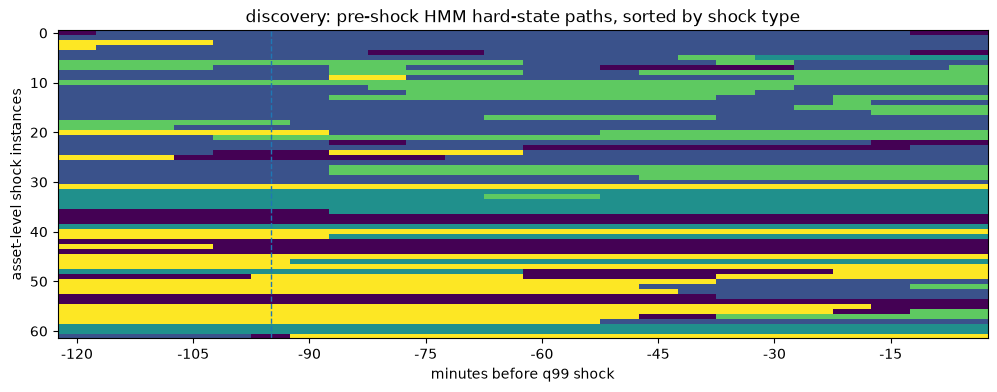

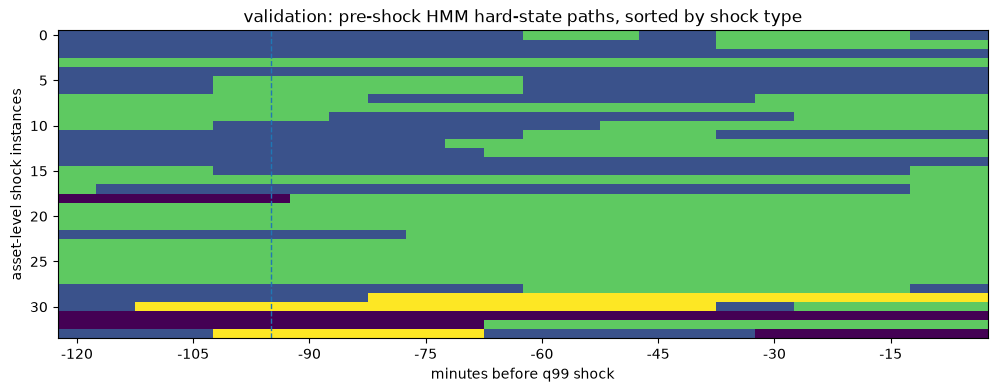

In [16]:
for sample, paths, assn in [('discovery',disc_paths,disc_assign),('validation',val_paths,val_assign)]:
    order = assn.sort_values(['shock_type','event_time','underlying']).event_id.astype(int).tolist()
    mat = []
    for eid in order:
        h = paths[paths.event_id == eid].sort_values('rel_bar')
        if len(h) == 24:
            mat.append(h.hard_state.to_numpy(int))
    if mat:
        fig, ax = plt.subplots(figsize=(12, max(4, min(14, len(mat)*0.06))))
        ax.imshow(np.vstack(mat), aspect='auto', interpolation='nearest')
        ax.axvline(v7.MOTIF_INDEX, linewidth=1, linestyle='--')
        ax.set_xticks(range(0,24,3), [v7.PRE_BARS[i]*5 for i in range(0,24,3)])
        ax.set_xlabel('minutes before q99 shock')
        ax.set_ylabel('asset-level shock instances')
        ax.set_title(f'{sample}: pre-shock HMM hard-state paths, sorted by shock type')
        plt.show()


## 16. Persist outputs


In [17]:
contract.to_csv(OUT / '07_feature_contract.csv', index=False)
events.to_csv(OUT / '07_q99_event_catalog_all.csv', index=False)
events_u.to_csv(OUT / '07_q99_event_catalog_usable.csv', index=False)
events_model.to_csv(OUT / '07_q99_event_catalog_model_sample.csv', index=False)
window_audit.to_csv(OUT / '07_window_audit.csv', index=False)
normalizer.to_csv(OUT / '07_source_hour_normalizer.csv', index=False)
coverage.to_csv(OUT / '07_family_window_coverage.csv', index=False)
hmm_compare.to_csv(OUT / '07_hmm_model_comparison.csv', index=False)
hmm_emissions.to_csv(OUT / '07_hmm_emissions.csv', index=False)
hmm_transitions.to_csv(OUT / '07_hmm_transitions.csv', index=False)
all_paths.to_csv(OUT / '07_event_state_paths.csv', index=False)
cluster_compare.to_csv(OUT / '07_shock_type_model_comparison.csv', index=False)
assignments.to_csv(OUT / '07_shock_assignments.csv', index=False)
family_profiles.to_csv(OUT / '07_shock_type_family_profiles.csv', index=False)
state_profiles.to_csv(OUT / '07_shock_type_state_profiles.csv', index=False)
descriptors.to_csv(OUT / '07_shock_type_descriptors.csv', index=False)
asset_composition.to_csv(OUT / '07_shock_type_asset_composition.csv', index=False)
date_composition.to_csv(OUT / '07_shock_type_date_composition.csv', index=False)
stability.to_csv(OUT / '07_validation_stability.csv', index=False)
sens_hmm_compare.to_csv(OUT / '07_sensitivity_hmm_comparison.csv', index=False)
sens_cluster_compare.to_csv(OUT / '07_sensitivity_shock_type_comparison.csv', index=False)
sensitivity.to_csv(OUT / '07_collector_sensitivity.csv', index=False)

embed_cols = [f'embedding_{i:02d}' for i in range(disc_embed_raw.shape[1])]
disc_emb_df = pd.DataFrame(disc_embed_raw, columns=embed_cols)
disc_emb_df.insert(0,'event_id',disc_events.event_id.to_numpy())
disc_emb_df['sample']='discovery'
val_emb_df = pd.DataFrame(val_embed_raw, columns=embed_cols)
val_emb_df.insert(0,'event_id',val_events.event_id.to_numpy())
val_emb_df['sample']='validation'
pd.concat([disc_emb_df,val_emb_df],ignore_index=True).to_csv(OUT / '07_event_embeddings.csv', index=False)

meta = {
    'version': v7.VERSION,
    'module': '07_q99_preshock_hmm_taxonomy',
    'question': 'Conditional on q99 occurring, are there distinct recurrent 120-minute pre-shock trajectories?',
    'event_definition': 'full-sample per-asset q99 native 5m variance onset, matching Modules 03-05',
    'hmm_window_minutes': [-120,-5],
    'hmm_window_bars': 24,
    'event_bar_t0_used_in_hmm': False,
    'post_event_data_used_in_hmm': False,
    'shock_outcomes_used_for_clustering': False,
    'family_emissions': family_names,
    'source_features': list(v7.SOURCE_FEATURES),
    'normalization': 'training/discovery-era asset x UTC hour robust z; source features transformed then averaged within Module05 families',
    'simultaneous_event_weighting': 'each unique q99 timestamp has total HMM/clustering weight 1 across assets',
    'hmm_selected_K': selected_k,
    'selected_n_shock_types': n_types,
    'discovery_validation_split_time': str(split_time),
    'taxonomy_validation': 'validation shocks assigned to frozen discovery centroids',
    'collector_sensitivity': 'full rerun with liquidity/book family reduced to spread only',
    'forecasting_claim': False,
    'regime_count_claim': False,
    'n_all_q99_asset_events': int(len(events)),
    'n_usable_q99_asset_events': int(len(events_u)),
    'n_usable_unique_event_times': int(events_u.event_time.nunique()),
    'min_l2_window_coverage_primary': MIN_L2_WINDOW_COVERAGE,
    'n_primary_l2_covered_asset_events': int(len(events_model)),
    'n_primary_l2_covered_unique_event_times': int(events_model.event_time.nunique()),
    'n_historical_missing_l2_projection_events': int(len(events_hist)),
}
(OUT / '07_run_metadata.json').write_text(json.dumps(meta, indent=2))
print('wrote Module 07 outputs to', OUT)


wrote Module 07 outputs to D:\Projects\deribit_market_data\notebooks\Volatility_Dynamics\07


## Interpretation boundary

A useful result is **not** merely a positive silhouette. We want several things simultaneously:

- multiple shock types with non-trivial effective support;
- visibly different precursor-family and state trajectories;
- the same types receiving material support in the chronological validation shocks;
- no type dominated by one asset, one date, the L2-collector era, or prior-q99 aftershocks;
- reasonable agreement with the spread-only collector sensitivity.

Historical pre-L2 shocks are projection-only and must not be used as evidence that the taxonomy validated. If the discovery/validation conditions fail, the correct conclusion is that the apparent heterogeneity is not yet stable. If they hold, Module 07 will have identified a genuine candidate **taxonomy of q99 precursor paths**, which is a different result from forecasting q99 occurrence.
